This notebook shows the 66.66% reduction in latency on the credit card fraud dataset from https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud. The method is early-exiting and building a cascaded system of models and this notebook demonstrates that reductions in compute-time are possible while preserving accuracy. 

In [3]:
%pip install requests

  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached certifi-2026.10.23-py3-none-any.whl.metadata (2.5 kB)
Using cached idna-3.20-py3-none-any.whl (69 kB)
Using cached certifi-2026.10.23-py3-none-any.whl (135 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [requests]
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import pandas as pd
from sklearn.neural_network import MLPClassifier
from utils import analyze, optimize, HyperplaneDecisionRealTime, Router, PathConfig, RouterConfig
from sklearn.model_selection import train_test_split
import time
import os
import numpy as np
from tqdm import tqdm

import warnings

In [5]:


# Suppress only RuntimeWarning
warnings.filterwarnings("ignore", category=RuntimeWarning)

def load_dataset():
    df = pd.read_csv('/Users/samrandall/Downloads/creditcard.csv')
    X = df[[col for col in df.columns if col.startswith('V')]].to_numpy()
    y = df['Class'].to_numpy()
    return X, y




Load the dataset and train a simple MLPClassifier. This will take 10 seconds.

In [6]:
X, y = load_dataset()
X_train, X_test, y_train, y_test = train_test_split(X, y)
model = MLPClassifier()
model.fit(X_train, y_train)

,hidden_layer_sizes,"(100,)"
,activation,'relu'
,solver,'adam'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,200
,shuffle,True
,random_state,None


In [ ]:
json_save_path = "creditcard_hyperplane.json"


# Load the rule from cached.
if os.path.exists(json_save_path):

    config = PathConfig(path_type="class", activation=0)
    router_config = RouterConfig(positive_path=config, negative_path=lambda x: model.predict(x).item())
    hd = HyperplaneDecisionRealTime.load(json_save_path)
    router = Router(hd, router_config.positive_path, router_config.negative_path)
else:
    router = analyze(model, X_train)
    router.decision.save(json_save_path)

## The rule that the moco anaylsis system found. 

In [ ]:
print("Rule information: W: {}, b: {}, t: {}".format(router.decision.W, router.decision.b, router.decision.t))

In [ ]:

for i in range(len(X)):
    router.forward(X[i:i+1])

start = time.time()
for i in tqdm(range(len(X))):
    router.forward(X[i:i+1])
end = time.time()
early_exit_time = end - start

for i in range(len(X)):
    model.predict(X[i:i+1])

start = time.time()
for i in tqdm(range(len(X))):
    model.predict(X[i:i+1])
end = time.time()
original_time = end - start

print("Original Time", original_time) # 13.354 seconds
print("Early Exit Time", early_exit_time) # 10.707 seconds

100%|██████████| 284807/284807 [00:09<00:00, 28956.62it/s]

Original Time 9.836697816848755
Early Exit Time 3.4806981086730957


In [10]:
start = time.time()

for i in range(len(X)):
    router.forward(X[i:i+1])
worst_case_latency = 0
routed_latencies = []
for i in tqdm(range(len(X))):
    
    s = time.time()
    router.forward(X[i:i+1])
    e = time.time()
    worst_case_latency = max(worst_case_latency, e - s)
    routed_latencies.append(e - s)


print("Routed", worst_case_latency)

for i in range(len(X)):
    model.predict(X[i:i+1])

base_latencies = []
worst_case_latency = 0
for i in tqdm(range(len(X))):
    s = time.time()
    model.predict(X[i:i+1])
    e = time.time()
    base_latencies.append(e - s)
    worst_case_latency = max(worst_case_latency, e - s)

print("original", worst_case_latency)

100%|██████████| 284807/284807 [00:03<00:00, 78406.83it/s]


Routed 0.0013208389282226562


100%|██████████| 284807/284807 [00:10<00:00, 27504.58it/s]

original 0.0035948753356933594


In [14]:
import matplotlib.pyplot as plt

In [19]:
routed_latencies = np.array(routed_latencies)
base_latencies = np.array(base_latencies)

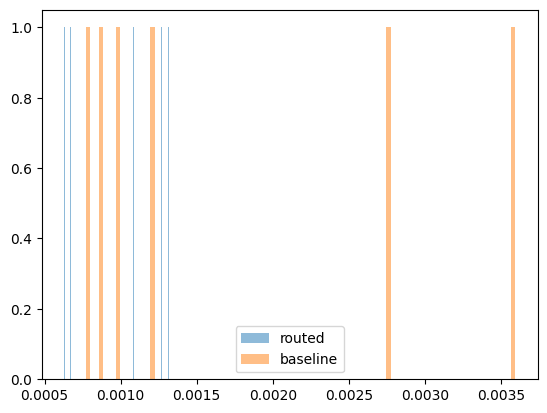

In [20]:
plt.hist(routed_latencies[routed_latencies > 0.0005], label = "routed", alpha = 0.5, bins = 100)
plt.hist(base_latencies[base_latencies > 0.0005], label = "baseline", alpha = 0.5, bins = 100)
plt.legend()
plt.show()

In [35]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

def predict(model, x):
    Z = x @ model.coefs_[0] + model.intercepts_[0]
    A = np.maximum(Z, 0)
    Z2 = A @ model.coefs_[1] + model.intercepts_[1]
    return sigmoid(Z2)

s = time.time()
for i in range(X.shape[0]):
    predict(model, X[i:i + 1])
e = time.time()
print("fast", e - s)

s = time.time()
for i in range(X.shape[0]):
    model.predict_proba(X[i:i + 1])
e = time.time()
print("model.predict", e - s)
    

fast 2.2973759174346924
model.predict 9.627731084823608


In [28]:
model.out_activation_

'logistic'

In [ ]:

s = time.time()
for i in range(X.shape[0]):
    predict(model, X[i: i + 1])
e = time.time()
e - s

s = time.time()
for i in range(X.shape[0]):
    model.predict(X[i: i + 1])
e = time.time()
e - s

2.297110080718994

9.932874917984009

In [12]:
p50, p95, p99, p999 = np.percentile(
    routed_latencies,
    [50, 95, 99, 99.9]
)
print("Routed")
print(f"p50:   {p50:.6f} s")
print(f"p95:   {p95:.6f} s")
print(f"p99:   {p99:.6f} s")
print(f"p99.9: {p999:.6f} s")

p50, p95, p99, p999 = np.percentile(
    base_latencies,
    [50, 95, 99, 99.9]
)
print("Baseline")
print(f"p50:   {p50:.6f} s")
print(f"p95:   {p95:.6f} s")
print(f"p99:   {p99:.6f} s")
print(f"p99.9: {p999:.6f} s")

Routed
p50:   0.000002 s
p95:   0.000041 s
p99:   0.000045 s
p99.9: 0.000116 s
Baseline
p50:   0.000037 s
p95:   0.000040 s
p99:   0.000056 s
p99.9: 0.000141 s


Counting how many data points avoided full model execution (were exited early)

In [24]:
decisions = []
for item in X:
    decisions.append(router.decision.forward(item[np.newaxis, :]))
decisions = np.array(decisions)

In [25]:
decisions.mean()

np.float64(0.7104846439869806)

## Latency 
The results in this run are that the original model took 14.04 seconds to run through the entire dataset of 284807 seconds. Compare this to Early Exit Latency of 4.68 seconds. This is a 66.7% reduction in CPU-time. Results vary based on the run of the algorithm. This is because 71% of the data points avoided model execution.

## Accuracy

This section shows below that the predictions in the routed model are 100% across the test set.

In [26]:
p = []
for item in X_test:
    p.append(router.forward(item[np.newaxis, :]))

early_exit_predictions = np.array(p)
original_predictions = model.predict(X_test)

In [27]:
np.mean(early_exit_predictions == original_predictions)

np.float64(1.0)